# LinearRegressionInference


In [8]:
from datascience import *
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

## Recap

In [9]:
def standard_units(arr):
    """ Converts an array to standard units """
    return (arr - np.average(arr))/np.std(arr)

def correlation(t, x, y):
    """ Computes correlation: t is a table, and x and y are column names """
    x_standard = standard_units(t.column(x))
    y_standard = standard_units(t.column(y))
    return np.average(x_standard * y_standard)

def slope(t, x, y):
    """ Computes the slope of the regression line, like correlation above """
    r = correlation(t, x, y)
    y_sd = np.std(t.column(y))
    x_sd = np.std(t.column(x))
    return r * y_sd / x_sd

def intercept(t, x, y):
    """ Computes the intercept of the regression line, like slope above """
    x_mean = np.mean(t.column(x))
    y_mean = np.mean(t.column(y))
    return y_mean - slope(t, x, y)*x_mean

def fitted_values(t, x, y):
    """Return an array of the regression estimates (predictions) at all the x values"""
    a = slope(t, x, y)
    b = intercept(t, x, y)
    return a*t.column(x) + b

def residuals(t, x, y):
    predictions = fitted_values(t, x, y)
    return t.column(y) - predictions

def plot_fitted(t, x, y):
    tbl = t.with_columns('Fitted', fitted_values(t, x, y))
    tbl.select(x, y, 'Fitted').scatter(0)

def plot_residuals(t, x, y):
    tbl = t.with_columns('Residual', residuals(t, x, y))
    tbl.scatter(x, 'Residual')

_________

In [10]:
demographics = Table.read_table('district_demographics2016.csv')
demographics.sample(6).show()

State,District,Median Income,Percent voting for Clinton,College%
California,"Congressional District 40 (115th Congress), California",42902,82.2,9.8
California,"Congressional District 17 (115th Congress), California",121150,73.9,57
North Carolina,"Congressional District 13 (115th Congress), North Carolina",47440,44,27
Texas,"Congressional District 6 (115th Congress), Texas",65758,41.9,28.7
West Virginia,"Congressional District 1 (115th Congress), West Virginia",45611,26.4,23.5
Michigan,"Congressional District 13 (115th Congress), Michigan",33995,78.8,14.7


**Linear Fit**

$\text{estimate of Median Income} = a \cdot \text{College\%} + b$

In [11]:
def local_average_income(college):
    """Return a prediction of Median Income from College%
    by averaging over districts with similar College% values.
    """
    a_little = 2
    close_points = demographics.where('College%', are.between(college - a_little, 
                                                              college + a_little))
    return close_points.column('Median Income').mean()   

with_averages = fitted_income.with_columns('Graph of Averages',
    demographics.apply(local_average_income, 'College%'))

with_averages.scatter('College%')

NameError: name 'fitted_income' is not defined

**STOP**

## New material

### Residual plots can tell us about our model fit

#### Case study 1: 2016 election demographics

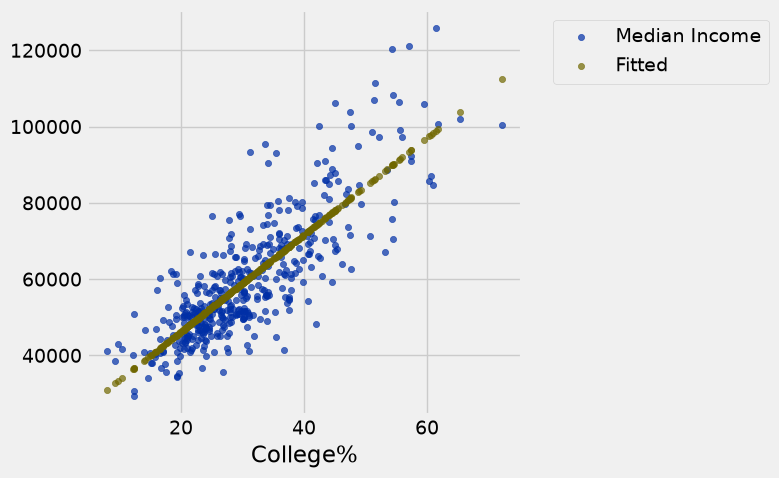

In [12]:
fitted_income = demographics.select('College%', 'Median Income')
fitted_income = fitted_income.with_columns('Fitted',
    fitted_values(demographics, 'College%', 'Median Income'))
fitted_income.scatter('College%')

In [13]:
income_residuals = fitted_income.with_columns(
    'Residual', residuals(demographics, 'College%', 'Median Income')
)
income_residuals.show(5)

College%,Median Income,Fitted,Residual
24,47083,51299.4,-4216.42
21.8,42035,48503.9,-6468.87
22.8,46544,49774.6,-3230.58
17,41110,42404.5,-1294.51
30.3,51690,59304.8,-7614.84


These two functions will help us plot things the rest of the way.

______

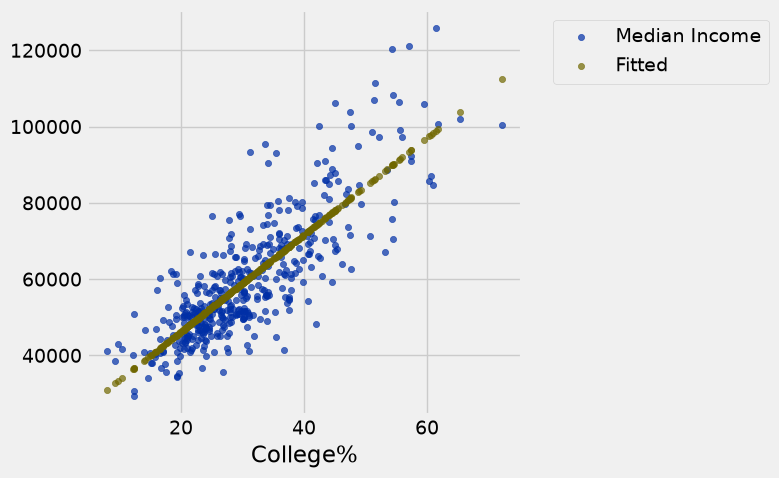

In [14]:
plot_fitted(demographics, 'College%', 'Median Income')

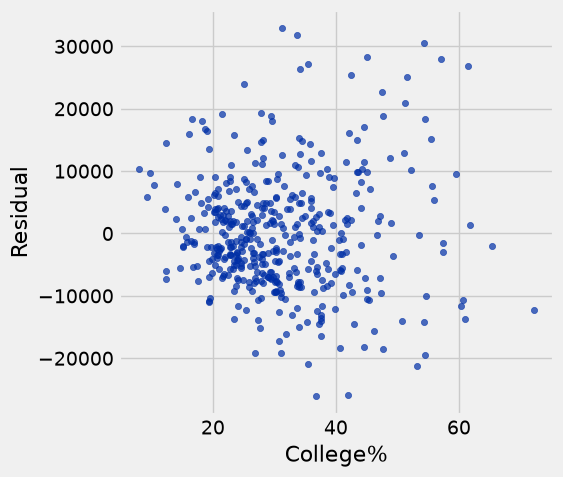

In [15]:
plot_residuals(demographics, 'College%', 'Median Income')

#### Case study 2: dugongs 

In [16]:
dugong = Table.read_table('dugong.csv')
dugong.show(5)

Length,Age
1.8,1
1.85,1.5
1.87,1.5
1.77,1.5
2.02,2.5


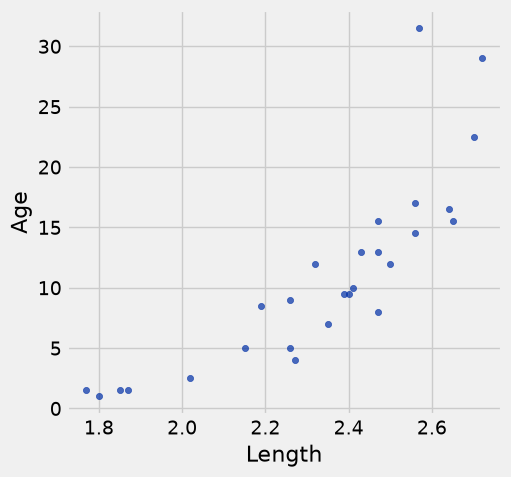

In [17]:
dugong.scatter('Length', 'Age')

In [18]:
correlation(dugong, 'Length', 'Age')

0.82964745549057139

$\text{estimate of Age} = a \cdot \text{Length} + b$

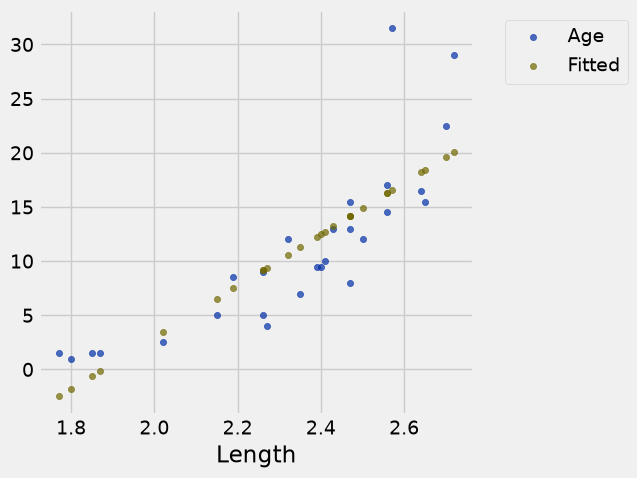

In [19]:
plot_fitted(dugong, 'Length', 'Age')

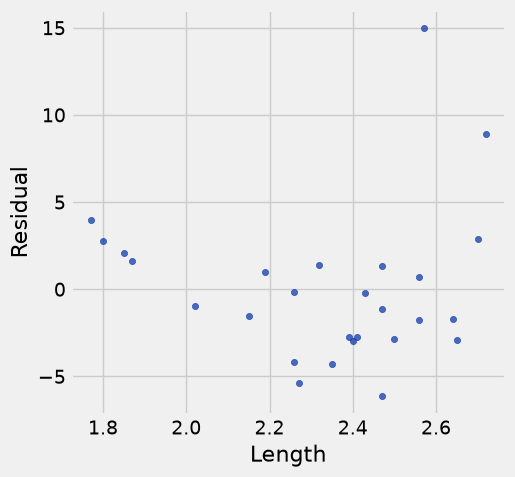

In [20]:
plot_residuals(dugong, 'Length', 'Age')

#### Case study 3: US women

In [21]:
us_women = Table.read_table('us_women.csv')
us_women.show(5)

height,ave weight
58,115
59,117
60,120
61,123
62,126


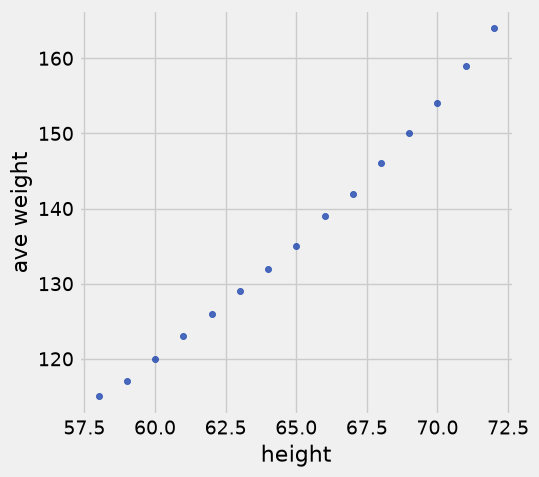

In [22]:
us_women.scatter('height')

In [23]:
correlation(us_women, 'height', 'ave weight')

0.99549476778421608

$\text{estimate of height} = a \cdot \text{average weight} + b$

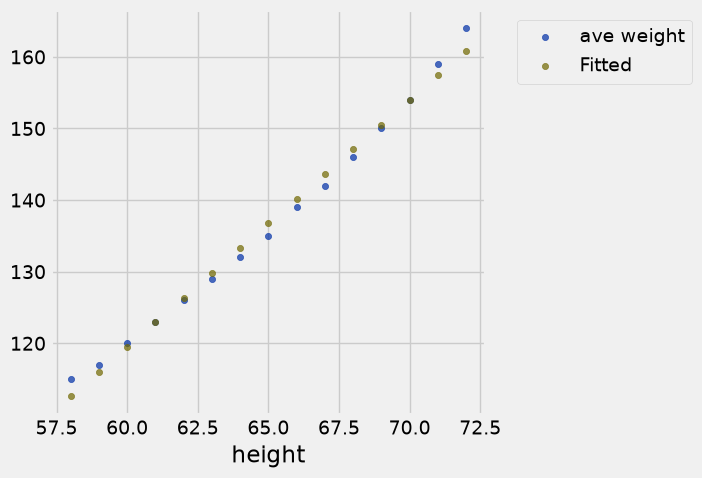

In [24]:
plot_fitted(us_women, 'height', 'ave weight')

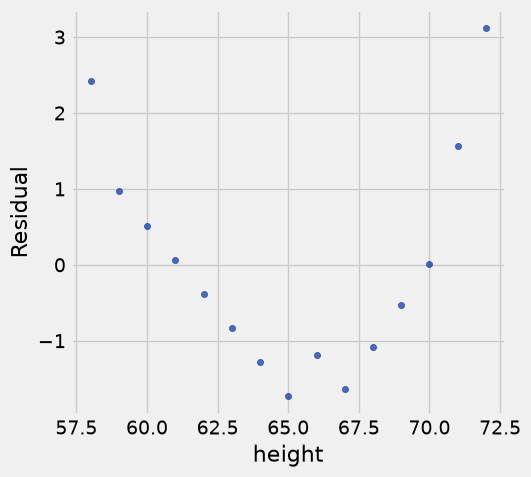

In [25]:
plot_residuals(us_women, 'height', 'ave weight')

#### Case study 4: Heights

In [26]:
family_heights = Table.read_table('family_heights.csv')
family_heights.where('family', '1')

family,father,mother,child,children,order,sex
1,78.5,67,73.2,4,1,male
1,78.5,67,69.2,4,2,female
1,78.5,67,69,4,3,female
1,78.5,67,69,4,4,female


In [27]:
parents = (family_heights.column('father') + family_heights.column('mother'))/2
heights = Table().with_columns(
    'Parent Average', parents,
    'Child', family_heights.column('child')
    )
heights.show(6)

Parent Average,Child
72.75,73.2
72.75,69.2
72.75,69
72.75,69
71,73.5
71,72.5


$\text{estimate of a child's adult height} = a \cdot \text{average parent height} + b$

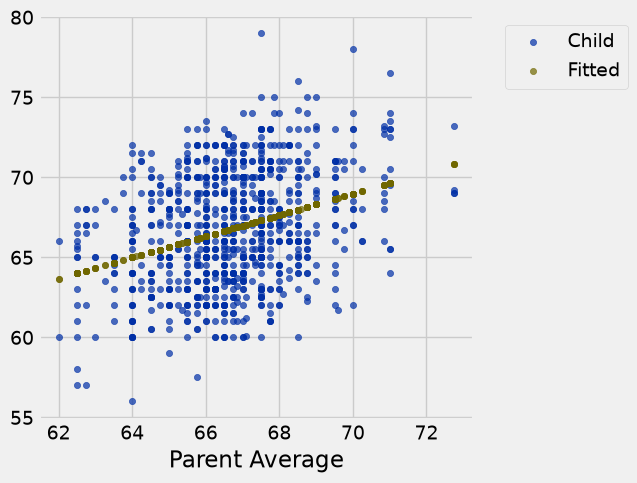

In [28]:
plot_fitted(heights, 'Parent Average', 'Child')

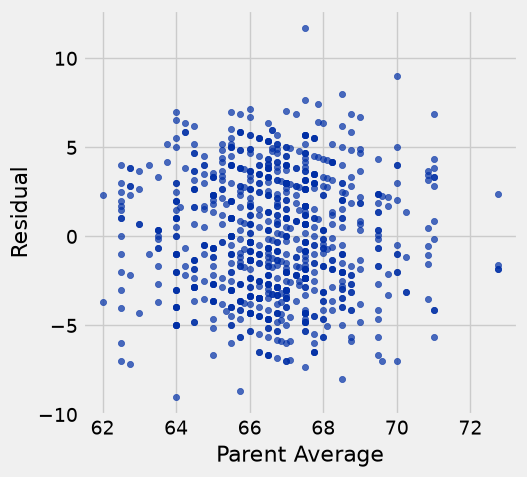

In [29]:
plot_residuals(heights, 'Parent Average', 'Child')

### Residuals have some special properties!

 The average of the residuals are zero.

In [30]:
round(np.average(residuals(demographics, 'College%', 'Median Income')), 10)

0.0

In [31]:
round(np.average(residuals(dugong, 'Length', 'Age')), 10)

0.0

In [32]:
round(np.average(residuals(heights, 'Parent Average', 'Child')), 10)

0.0

The correlation coefficients between:

- The residuals and $x$
- The residuals and the fitted values

are both 0.

In [33]:
heights = heights.with_columns(
    'Residual', residuals(heights, 'Parent Average', 'Child'),
    'Fitted Value', fitted_values(heights, 'Parent Average', 'Child')
)

In [34]:
round(correlation(heights, 'Parent Average', 'Residual'), 10)

0.0

In [35]:
round(correlation(heights, 'Fitted Value', 'Residual'), 10)

0.0

The standard deviation of the residuals is equal to $\sqrt{1 - r^2} \cdot \mbox{SD of }y.$

- $\mbox{SD of residuals} = \sqrt{1 - r^2} \cdot \mbox{SD of }y$

In [36]:
r = correlation(heights, 'Parent Average', 'Child')

In [37]:
np.std(residuals(heights, 'Parent Average', 'Child'))

3.3862655542854498

In [38]:
((1-r ** 2) ** 0.5) * np.std(heights.column('Child')) 

3.3862655542854494

Here is another way to think about $r$ and its square!

$$
\frac{\mbox{SD of fitted values}}{\mbox{SD of }y} ~=~ \vert r \vert
$$

In [39]:
np.std(fitted_values(heights, 'Parent Average', 'Child'))/np.std(heights.column('Child')) 

0.32244267720033065

In [40]:
abs(r)

0.32244267720033076

$$
\frac{\mbox{SD of fitted values}^2}{\mbox{SD of }y^2}= \frac{\mbox{variance of fitted values}}{\mbox{variance of }y} ~=~  r^2
$$

## New material

In [41]:
def standard_units(arr):
    return (arr - np.average(arr))/np.std(arr)

def correlation(t, x, y):
    x_standard = standard_units(t.column(x))
    y_standard = standard_units(t.column(y))
    return np.average(x_standard * y_standard)

def slope(t, x, y):
    r = correlation(t, x, y)
    y_sd = np.std(t.column(y))
    x_sd = np.std(t.column(x))
    return r * y_sd / x_sd

def intercept(t, x, y):
    x_mean = np.mean(t.column(x))
    y_mean = np.mean(t.column(y))
    return y_mean - slope(t, x, y)*x_mean

In [42]:
def fitted_values(t, x, y):
    """Return an array of the regression estimates at all the x values"""
    a = slope(t, x, y)
    b = intercept(t, x, y)
    return a*t.column(x) + b

def residuals(t, x, y):
    """Return an array of all the residuals"""
    predictions = fitted_values(t, x, y)
    return t.column(y) - predictions

In [43]:
births = Table.read_table('baby.csv')
births.sample(3).show()

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
102,286,22,64,140,False
120,269,40,63,130,False
143,281,28,65,135,True


We will do a little bit of exploration, like always.

In [44]:
births = Table.read_table('baby.csv')
births.show(3)

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
128,279,28,64,115,True


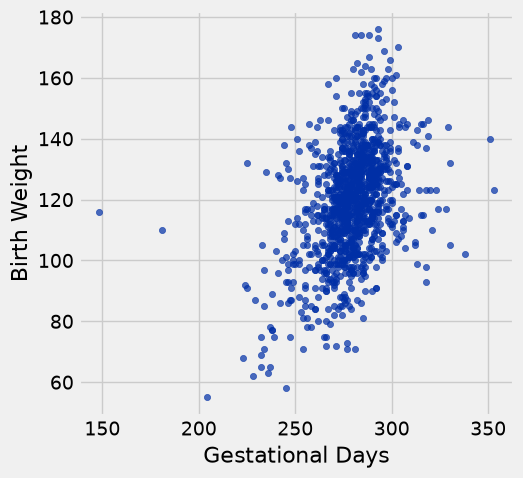

In [45]:
births.scatter('Gestational Days', 'Birth Weight')

In [46]:
correlation(births, 'Gestational Days', 'Birth Weight')

0.40754279338885108

Preterm and postterm pregnancy cutoffs, according to the CDC.

In [47]:
# Preterm and postterm pregnancy cutoffs, according to the CDC
make_array(37 * 7, 42 * 7)

array([259, 294])

In [48]:
births = births.where('Gestational Days', are.between(225, 325))

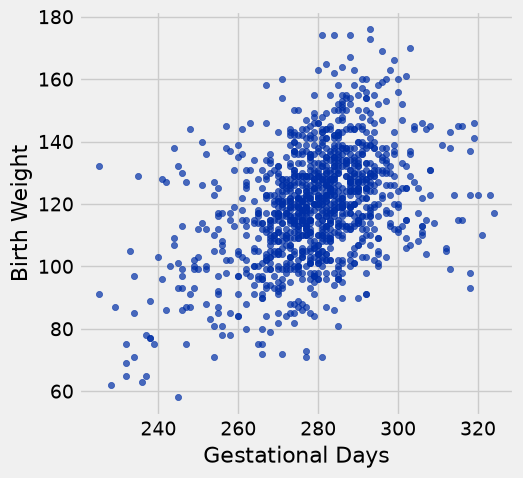

In [49]:
births.scatter('Gestational Days', 'Birth Weight')

In [50]:
correlation(births, 'Gestational Days', 'Birth Weight')

0.42295118452423991

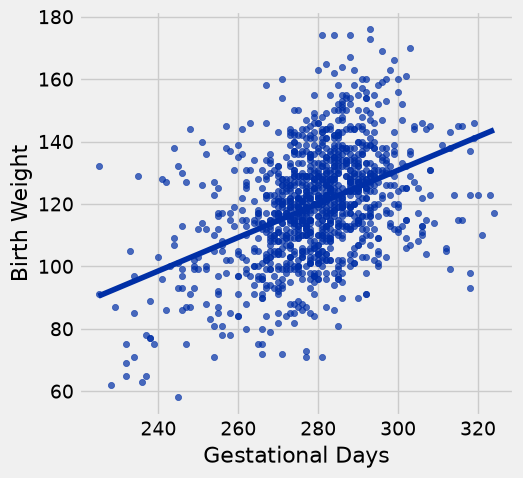

In [51]:
births.scatter('Gestational Days', 'Birth Weight', fit_line=True)

### A model consists of signal and noise

Ignore this code; it produces plots for demonstrating the regression model and has no conceptual value. The points created will differ each time this piece of code is run.

In [52]:
def draw_and_compare(true_slope, true_int, sample_size):
    x = np.random.normal(50, 5, sample_size)
    xlims = np.array([np.min(x), np.max(x)])
    errors = np.random.normal(0, 6, sample_size)
    y = (true_slope * x + true_int) + errors
    sample = Table().with_columns('x', x, 'y', y)

    sample.scatter('x', 'y')
    plots.plot(xlims, true_slope*xlims + true_int, lw=2, color='green')
    plots.title('True Line, and Points Created')

    sample.scatter('x', 'y')
    plots.title('What We Get to See')

    sample.scatter('x', 'y', fit_line=True)
    plots.title('Regression Line: Estimate of True Line')

    sample.scatter('x', 'y', fit_line=True)
    plots.plot(xlims, true_slope*xlims + true_int, lw=2, color='green')
    plots.title("Regression Line and True Line")

Sample size = 10

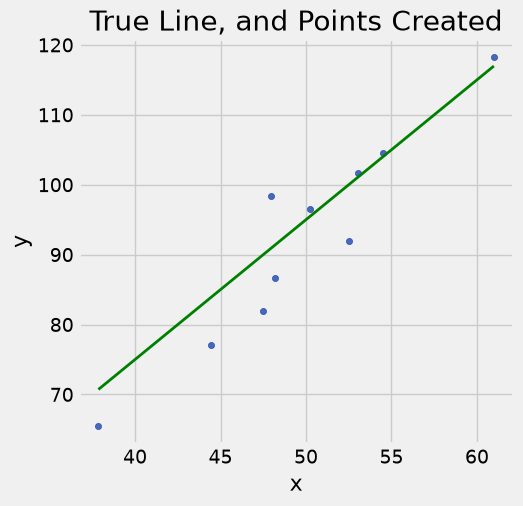

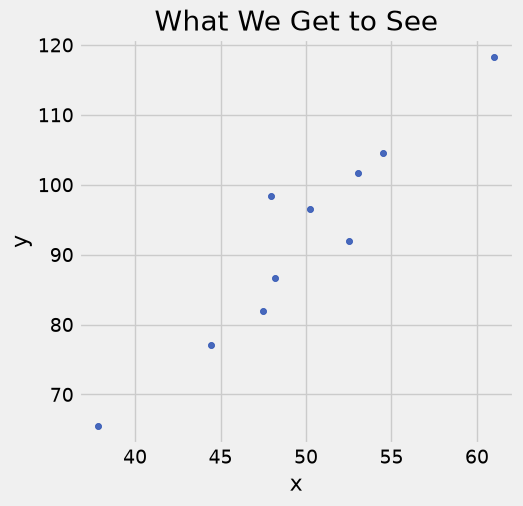

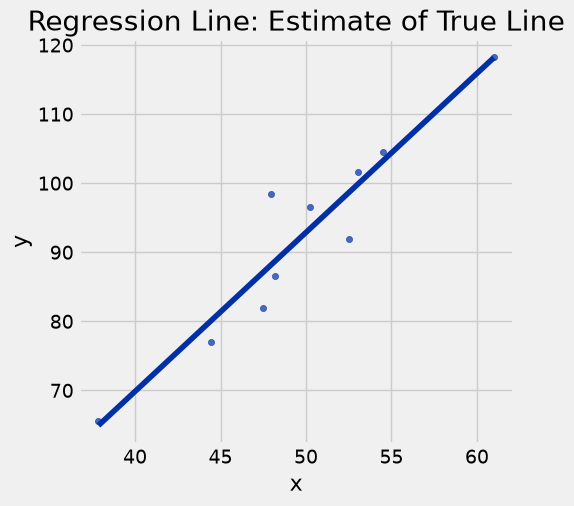

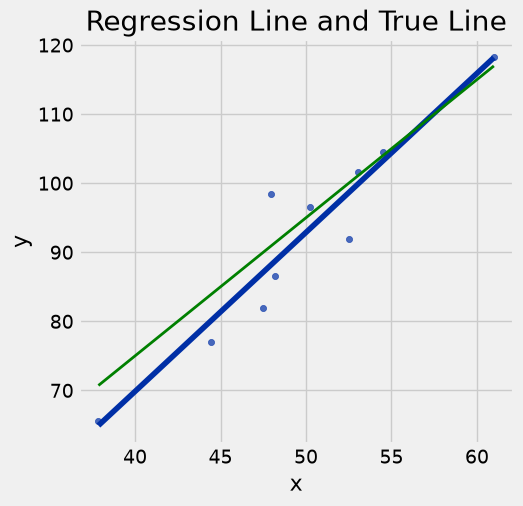

In [53]:
draw_and_compare(true_slope=2, true_int=-5, sample_size=10)

Sample size = 100

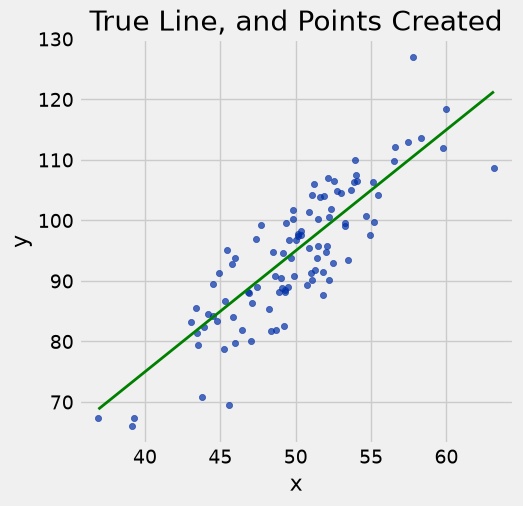

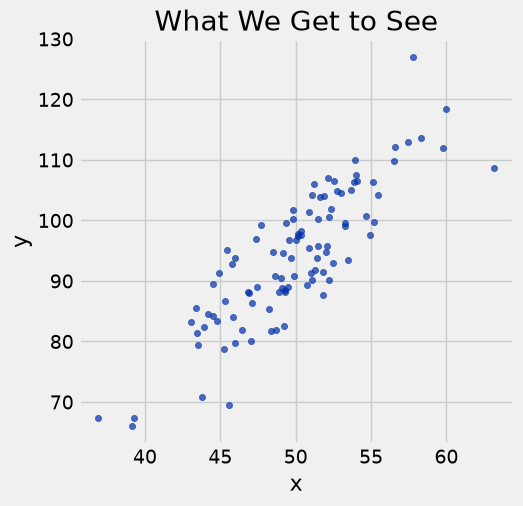

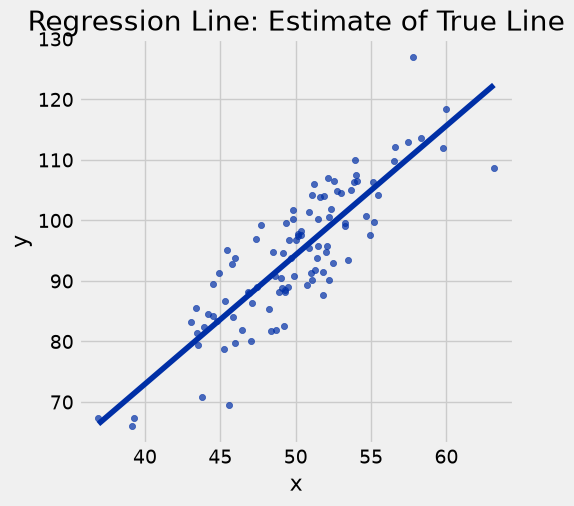

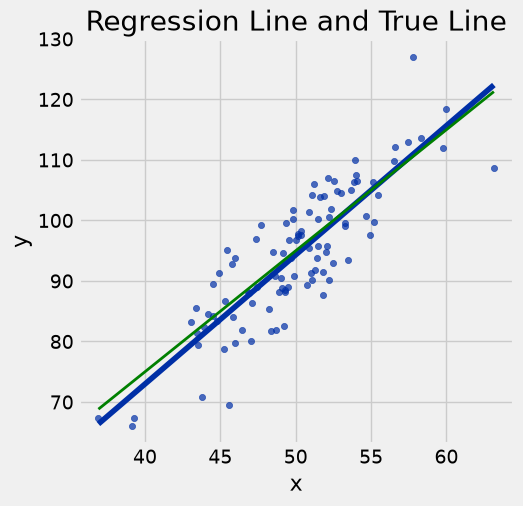

In [54]:
draw_and_compare(true_slope=2, true_int=-5, sample_size=100)

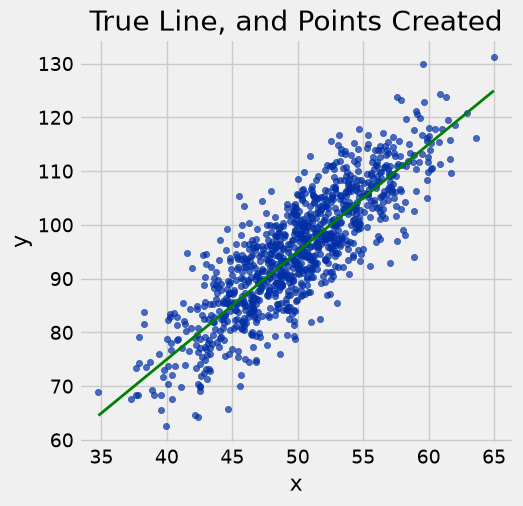

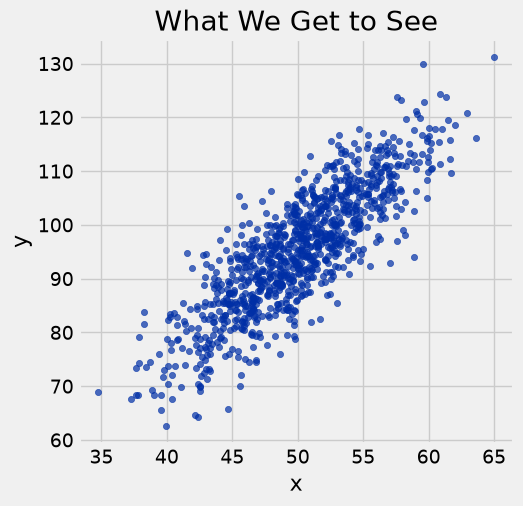

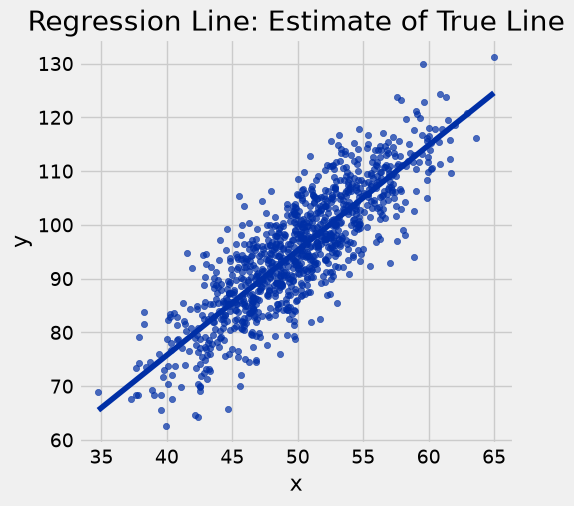

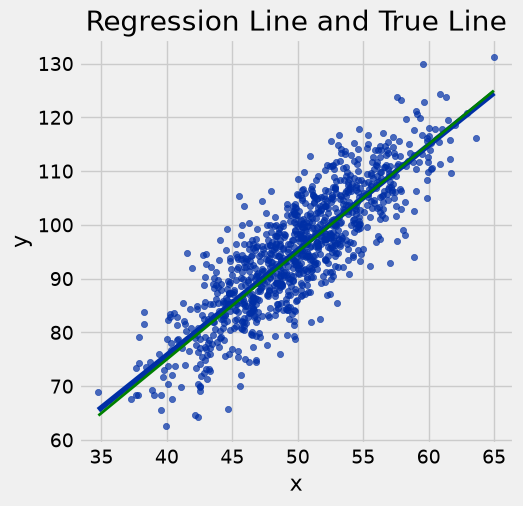

In [55]:
draw_and_compare(true_slope=2, true_int=-5, sample_size=1000) 

**STOP**

### Can we give an estimate for the **true** relationship between two numerical variables $x$ and $y$?

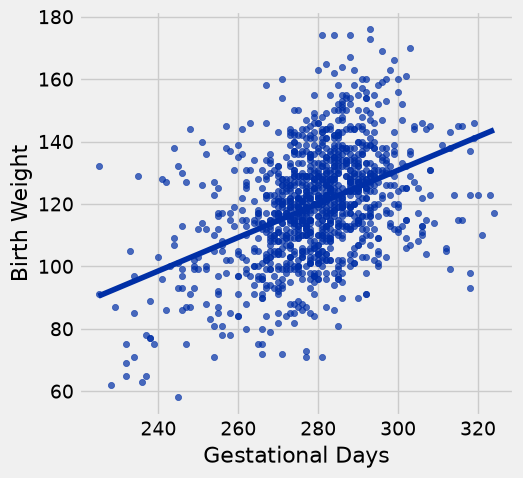

In [56]:
births.scatter('Gestational Days', 'Birth Weight', fit_line=True)

In [64]:
slope(births, 'Gestational Days', 'Birth Weight')

0.53784536766790358

In [66]:
def bootstrap_slope_interval(t, x, y, repetitions=2500):
    """ 
    Makes a 95% confidence interval for the slope of the true line, 
    using linear regression on the data in t (column names x and y).
    Shows a histogram of the bootstrap samples and shows the interval
    in gold.
    """
    
    # Bootstrap the scatter, find the slope, collect
    slopes = make_array()
    for i in np.arange(repetitions):
        bootstrap_sample = t.sample()
        bootstrap_slope = slope(bootstrap_sample, x, y)
        slopes = np.append(slopes, bootstrap_slope)
    
    # Find the endpoints of the 95% confidence interval for the true slope
    left = percentile(2.5, slopes)
    right = percentile(97.5, slopes)
    round_left = round(left, 3)
    round_right = round(right, 3)
    
    # Slope of the regression line from the original sample
    observed_slope = slope(t, x, y)
    
    # Display results (no need to follow this code)
    Table().with_column('Bootstrap Slopes', slopes).hist(bins=20)
    plots.plot(make_array(left, right), make_array(0, 0), color='yellow', lw=8);
    print('Slope of regression line:', round(observed_slope, 3))
    print('Approximate 95%-confidence interval for the slope of the true line:')
    print(round_left, 'to', round_right)

Slope of regression line: 0.538
Approximate 95%-confidence interval for the slope of the true line:
0.46 to 0.616


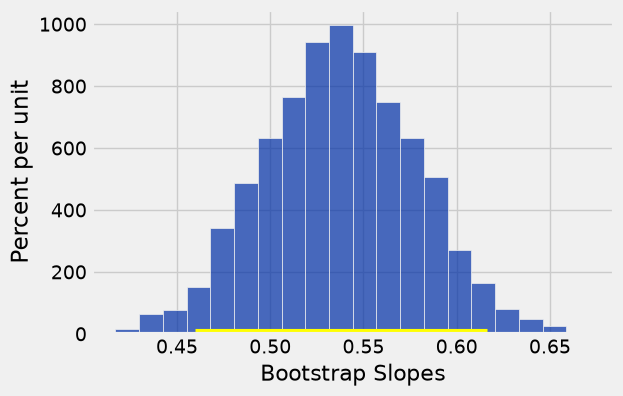

In [67]:
bootstrap_slope_interval(births, 'Gestational Days', 'Birth Weight')

**STOP**

### What if the true line is actually *flat*?! 

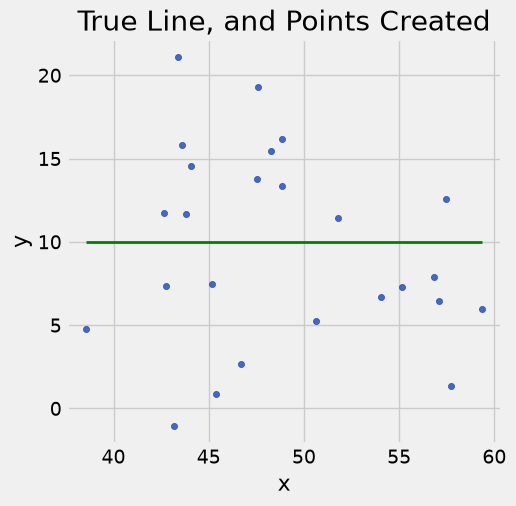

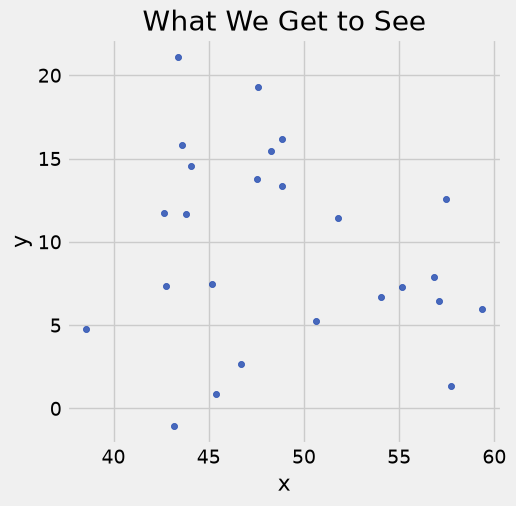

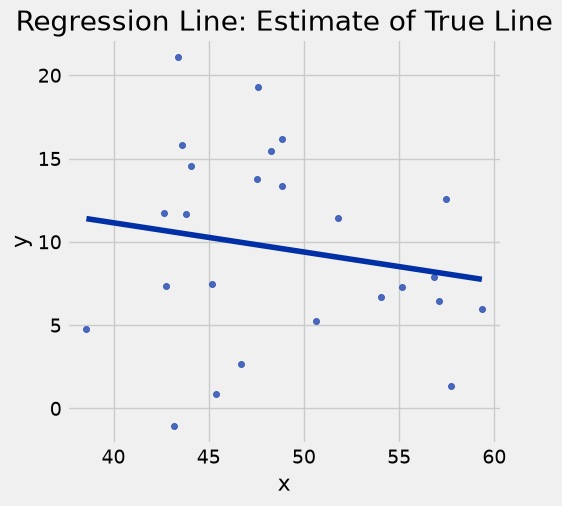

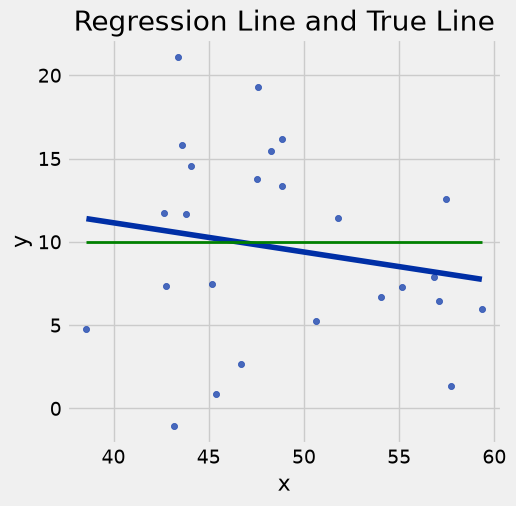

In [60]:
draw_and_compare(true_slope=0, true_int=10, sample_size=25)

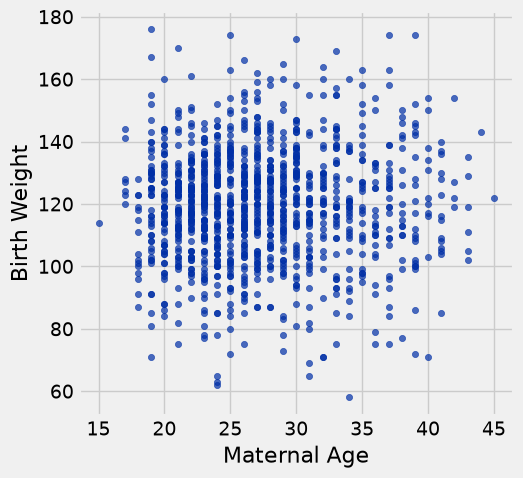

In [61]:
births.scatter('Maternal Age', 'Birth Weight')

In [62]:
slope(births, 'Maternal Age', 'Birth Weight')

0.095142237298344659

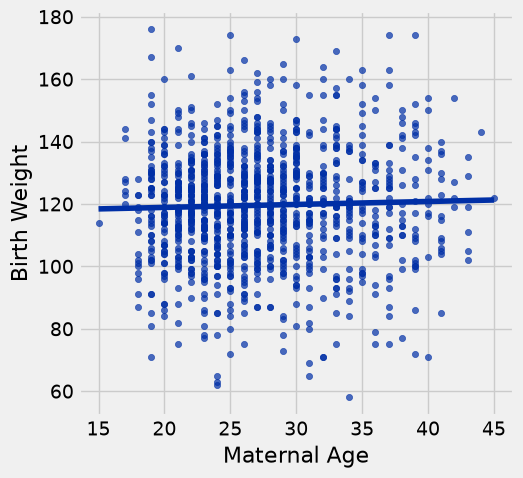

In [63]:
births.scatter('Maternal Age', 'Birth Weight', fit_line=True)

**Null:** Slope of true line is equal to 0.

**Alternative:** Slope of true line is not equal to 0.

Slope of regression line: 0.095
Approximate 95%-confidence interval for the slope of the true line:
-0.094 to 0.289


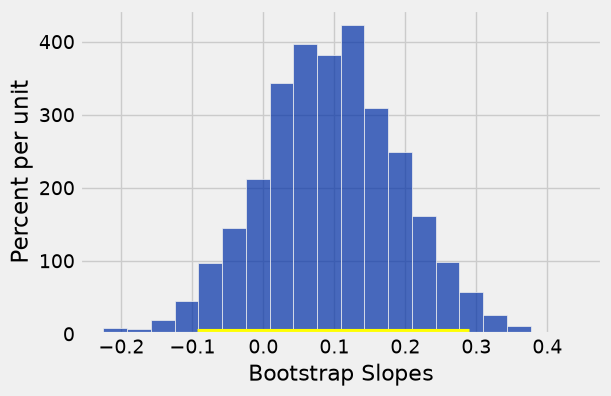

In [68]:
bootstrap_slope_interval(births, 'Maternal Age', 'Birth Weight')

### Can we predict the response of a new individual who is **not** in our sample?

In [69]:
def prediction_at(t, x, y, x_value):
    '''
    t - table
    x - label of x column
    y - label of y column
    x_value - the x value for which we want to predict y
    '''
    return slope(t, x, y) * x_value + intercept(t, x, y)

In [70]:
prediction_at_300 = prediction_at(births, 'Gestational Days', 'Birth Weight', 300)
prediction_at_300

130.80951674248769

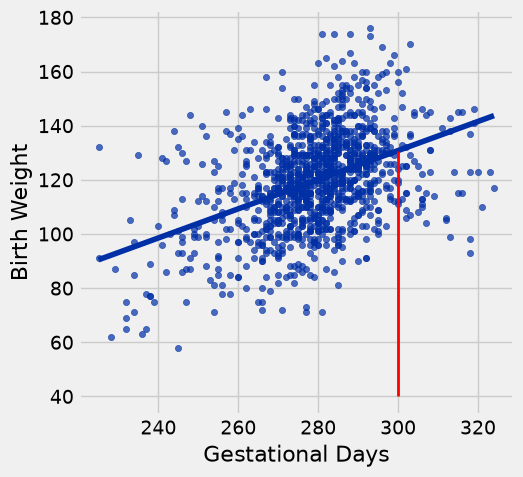

In [71]:
x = 300
births.scatter('Gestational Days', 'Birth Weight', fit_line=True)
plots.plot([x, x], [40, prediction_at_300], color='red', lw=2);

- You don't need to understand the plotting code in this cell, but you should understand the figure that comes out.

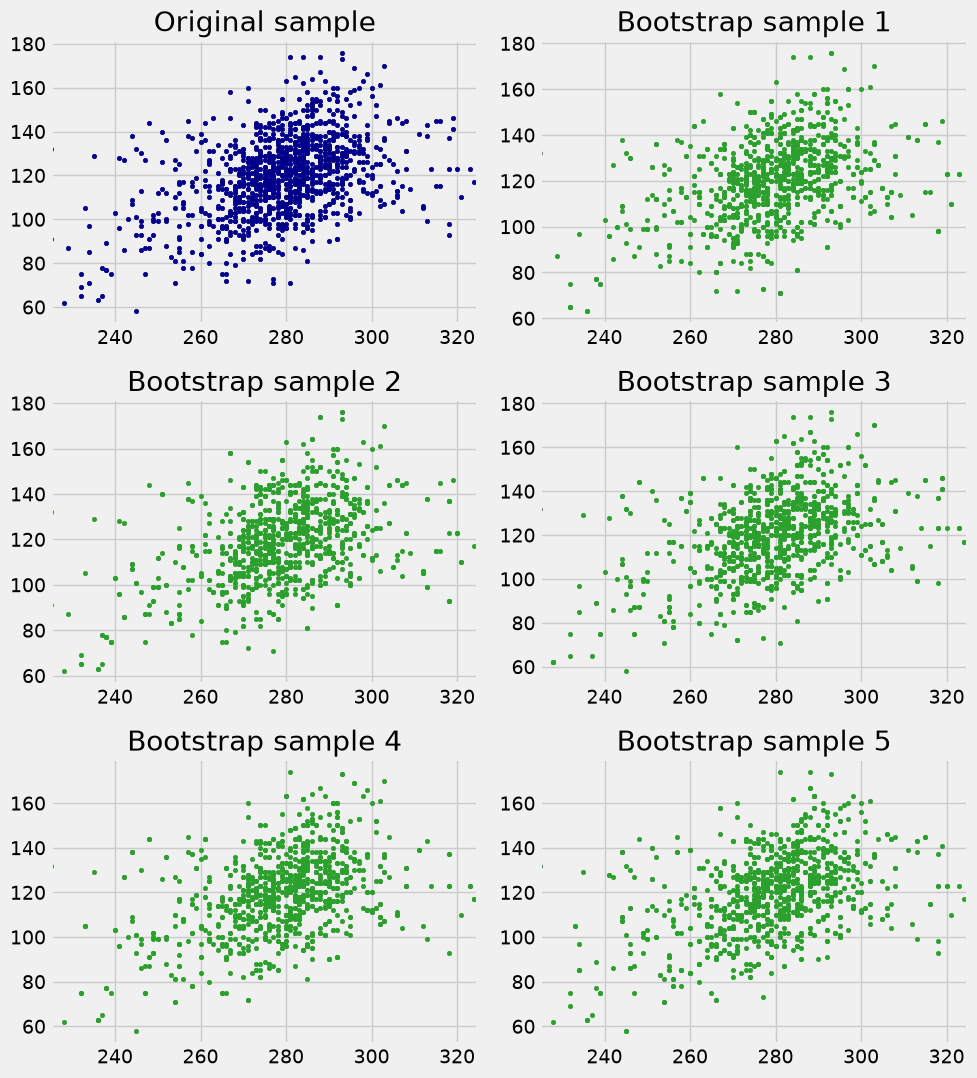

In [72]:
plots.figure(figsize=(10, 11))
plots.subplot(3, 2, 1)
plots.scatter(births[1], births[0], s=10, color='darkblue')
plots.xlim([225, 325])
plots.title('Original sample')

for i in np.arange(1, 6, 1):
    plots.subplot(3,2,i+1)
    resampled = births.sample()
    plots.scatter(resampled.column('Gestational Days'), resampled.column('Birth Weight'), s=10, color='tab:green')
    plots.xlim([225, 325])
    plots.title('Bootstrap sample '+str(i))
plots.tight_layout()

Predicted y from bootstrap sample was 130.446669696
Predicted y from bootstrap sample was 131.257652253
Predicted y from bootstrap sample was 131.041726025
Predicted y from bootstrap sample was 131.397143387


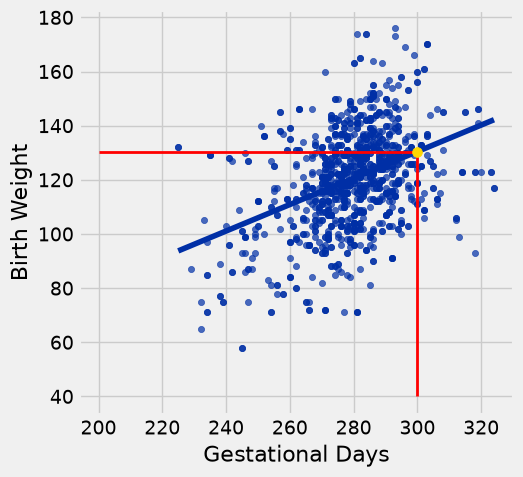

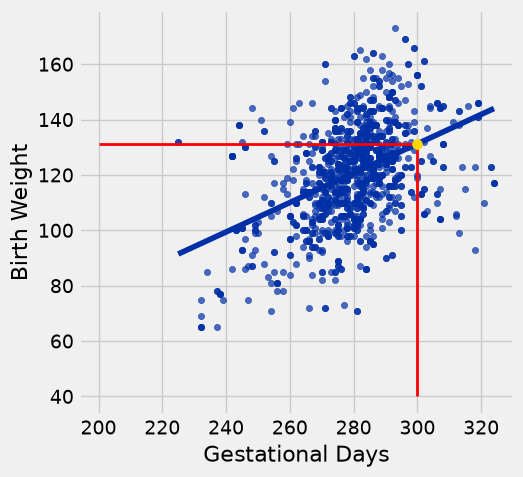

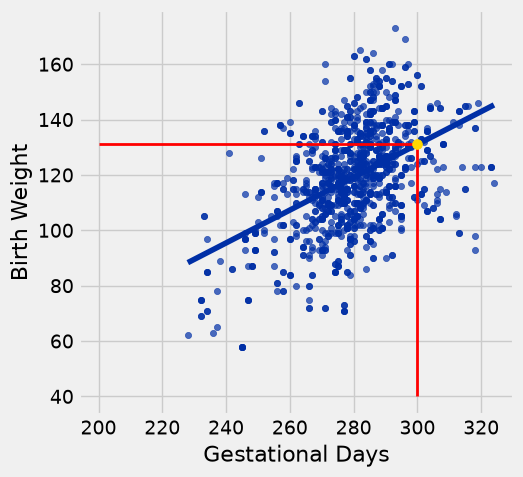

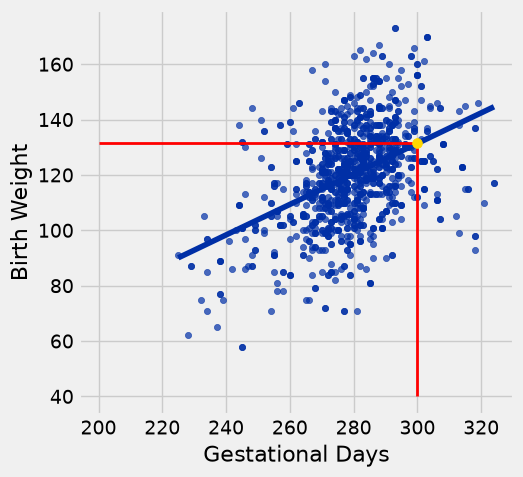

In [73]:
for i in np.arange(4):
    resample = births.sample()
    predicted_y = prediction_at(resample, 'Gestational Days', 'Birth Weight', 300)
    print('Predicted y from bootstrap sample was', predicted_y)
    resample.scatter('Gestational Days', 'Birth Weight', fit_line=True)
    plots.scatter(300, predicted_y, color='gold', s=50, zorder=3);
    plots.plot([x, x], [40, predicted_y], color='red', lw=2);
    plots.plot([200, x], [predicted_y, predicted_y], color='red', lw=2);

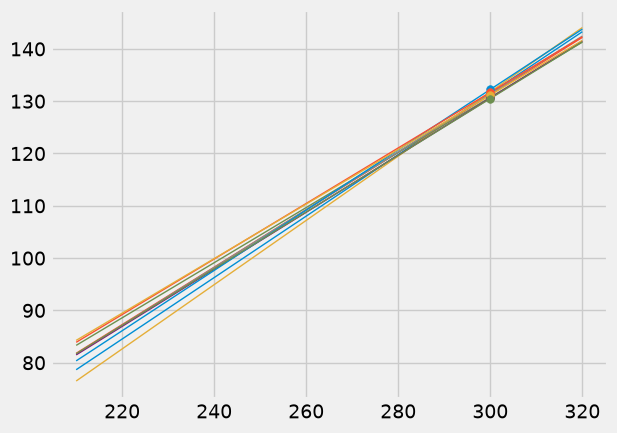

In [74]:
lines = Table(['slope','intercept', 'at 210', 'at 300', 'at 320'])

for i in range(10):
    resample = births.sample()
    a = slope(resample, 'Gestational Days', 'Birth Weight')
    b = intercept(resample, 'Gestational Days', 'Birth Weight')
    lines.append([a, b, a * 210 + b, a * 300 + b, a * 320 + b])

for i in np.arange(lines.num_rows):
    line = lines.row(i)
    plots.plot([210, 320], [line.item('at 210'), line.item('at 320')], lw=1)
    plots.scatter(300, line.item('at 300'), s=30, zorder=3)

In [75]:
np.mean(births.column('Gestational Days')), np.mean(births.column('Birth Weight'))

(279.11015490533561, 119.57401032702238)

In [76]:
lines = Table(['slope','intercept', 'at 291', 'at 300', 'at 309'])

for i in range(10):
    resample = births.sample()
    a = slope(resample, 'Gestational Days', 'Birth Weight')
    b = intercept(resample, 'Gestational Days', 'Birth Weight')
    lines.append([a, b, a * 291 + b, a * 300 + b, a * 309 + b])
lines


slope,intercept,at 291,at 300,at 309
0.552216,-33.8254,126.869,131.839,136.809
0.536763,-30.8287,125.369,130.2,135.031
0.496066,-17.7057,126.649,131.114,135.579
0.529104,-28.4253,125.544,130.306,135.068
0.590223,-44.2994,127.456,132.768,138.08
0.553683,-34.5647,126.557,131.54,136.523
0.528539,-27.8449,125.96,130.717,135.474
0.501248,-20.5248,125.338,129.85,134.361
0.520313,-25.4176,125.994,130.676,135.359
0.513456,-23.8985,125.517,130.138,134.76


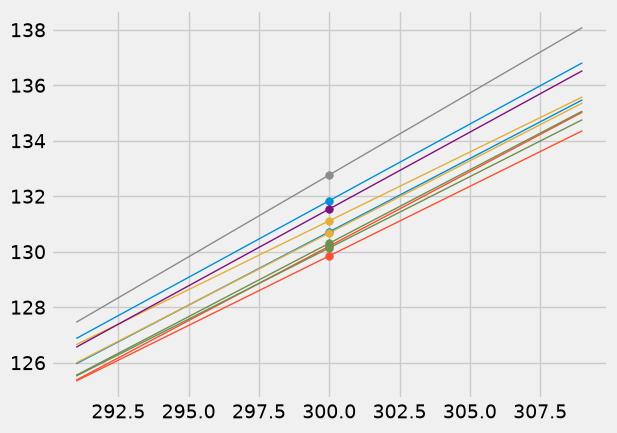

In [77]:
for i in np.arange(lines.num_rows):
    line = lines.row(i)
    plots.plot([291, 309], [line.item('at 291'), line.item('at 309')], lw=1)
    plots.scatter(300, line.item('at 300'), s=30, zorder=3)

______

In [80]:
def bootstrap_prediction(t, x, y, new_x, repetitions=2500):
    """ 
    Makes a 95% confidence interval for the height of the true line at new_x, 
    using linear regression on the data in t (column names x and y).
    Shows a histogram of the bootstrap samples and shows the interval
    in gold.
    """

    # Bootstrap the scatter, predict, collect
    predictions = make_array()
    for i in np.arange(repetitions):
        resample = t.sample()
        predicted_y = prediction_at(resample, x, y, new_x)
        predictions = np.append(predictions, predicted_y)

    # Find the ends of the approximate 95% prediction interval
    left = percentile(2.5, predictions)
    right = percentile(97.5, predictions)
    round_left = round(left, 3)
    round_right = round(right, 3)

    # Display results
    Table().with_column('Prediction', predictions).hist(bins=20)
    plots.xlabel('predictions at x='+str(new_x))
    plots.plot([left, right], [0, 0], color='yellow', lw=8);
    print('Approximate 95%-confidence interval for height of true line at x =', new_x)
    print(round_left, 'to', round_right, '( width =', round(right - left, 3), ')') 

**STOP**

### The prediction interval depends on the value of $x$

Approximate 95%-confidence interval for height of true line at x = 300
128.902 to 132.671 ( width = 3.769 )


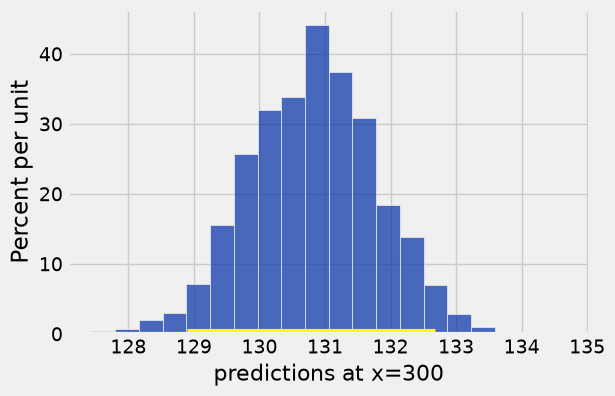

In [81]:
bootstrap_prediction(births, 'Gestational Days', 'Birth Weight', 300)

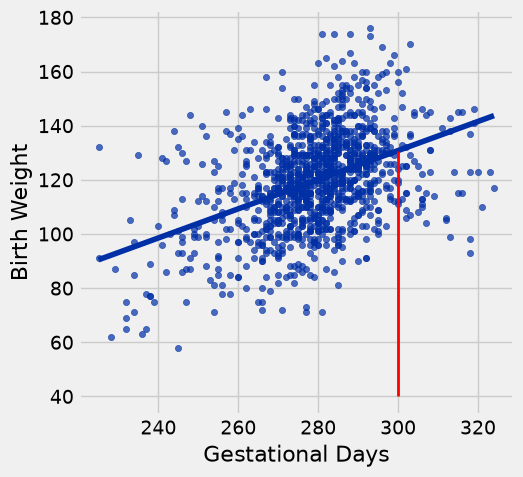

In [82]:
x = 300
births.scatter('Gestational Days', 'Birth Weight', fit_line=True)
plots.plot([x, x], [40, prediction_at_300], color='red', lw=2);

Approximate 95%-confidence interval for height of true line at x = 230
89.121 to 97.509 ( width = 8.388 )


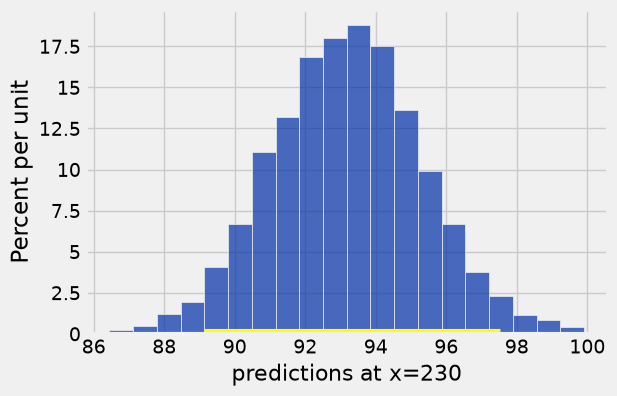

In [83]:
bootstrap_prediction(births, 'Gestational Days', 'Birth Weight', 230)

Approximate 95%-confidence interval for height of true line at x = 280
119.129 to 120.97 ( width = 1.841 )


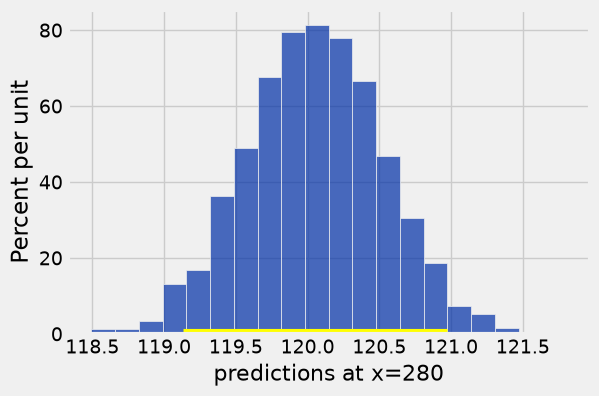

In [84]:
bootstrap_prediction(births, 'Gestational Days', 'Birth Weight', 280)

No need to follow the code in this cell; just understand the graph that comes out.

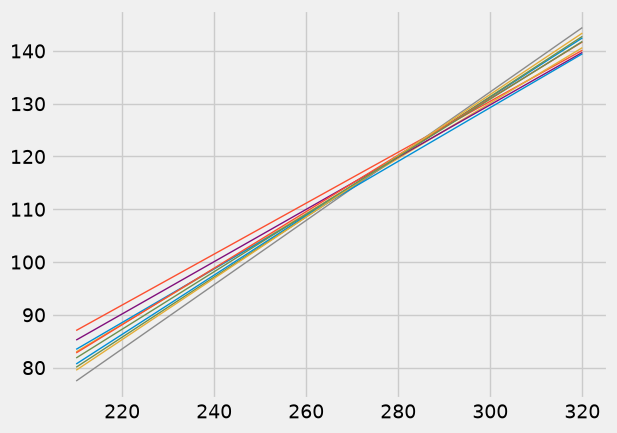

In [85]:
lines = Table(['slope','intercept', 'at 210', 'at 300', 'at 320'])

for i in range(10):
    resample = births.sample()
    a = slope(resample, 'Gestational Days', 'Birth Weight')
    b = intercept(resample, 'Gestational Days', 'Birth Weight')
    lines.append([a, b, a * 210 + b, a * 300 + b, a * 320 + b])

for i in np.arange(lines.num_rows):
    line = lines.row(i)
    plots.plot([210, 320], [line.item('at 210'), line.item('at 320')], lw=1)